# Healthcare Data Analytics: Exploratory Data Analysis & Business Insights 


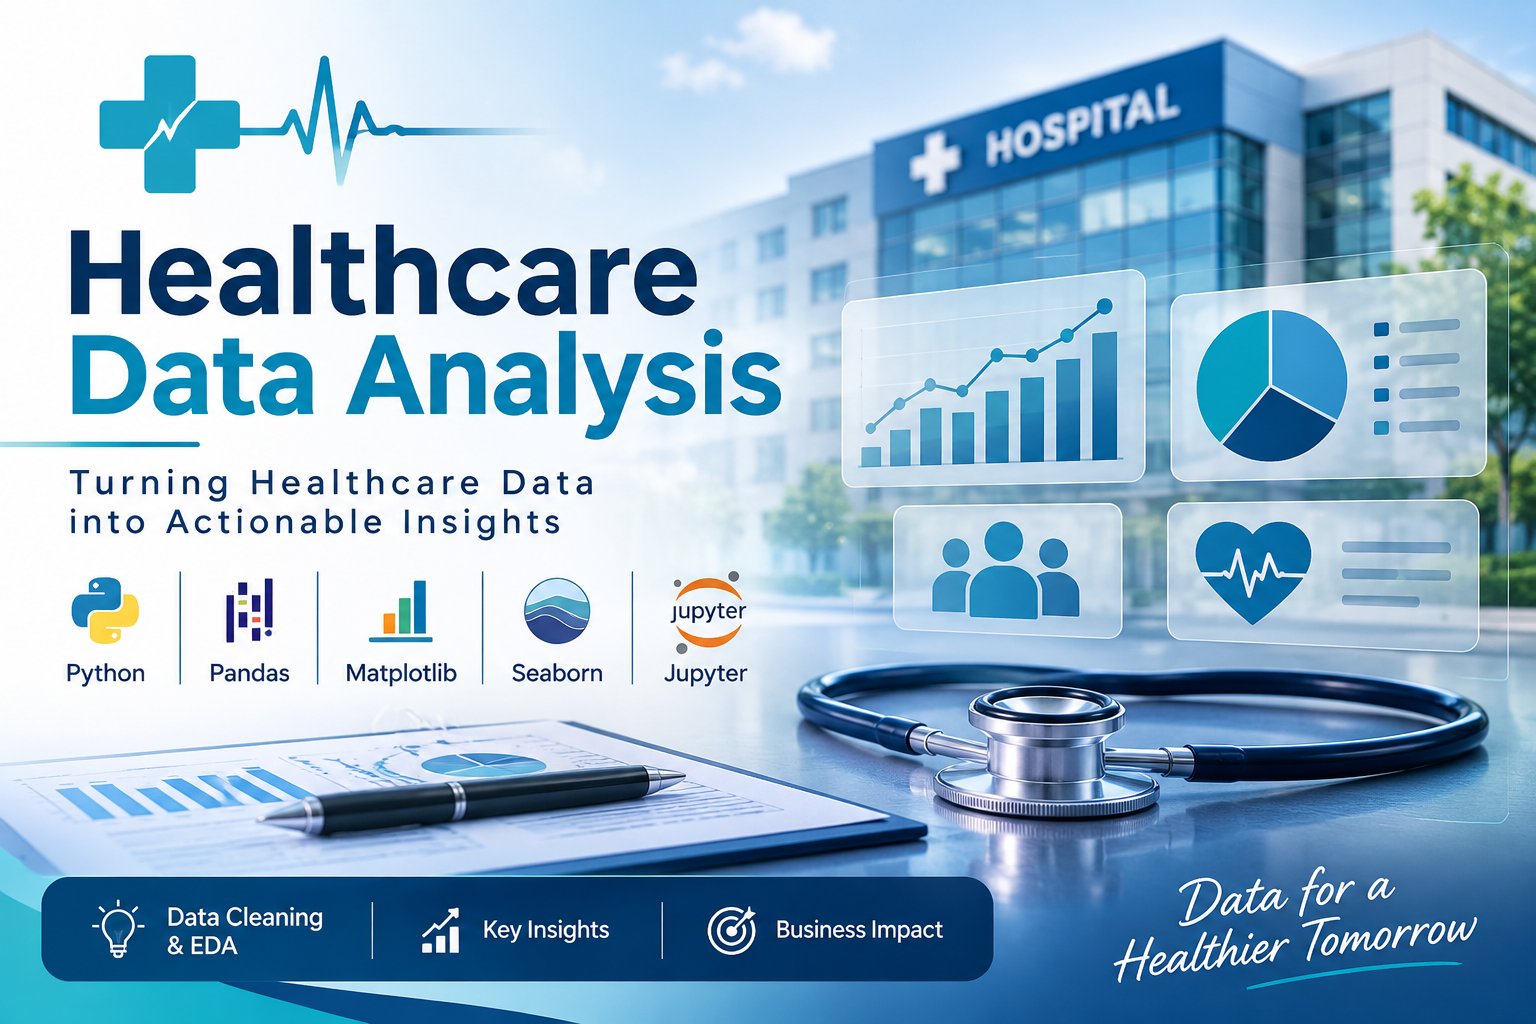

In [4]:
from IPython.display import Image, display

display(Image(filename='Healthcare Data Analysis Banner.png', width=1000))

# 🏥 Healthcare Data Analysis | Python & Data Analytics

## Project Overview

This project focuses on analyzing healthcare data to identify patient trends, treatment costs, admission patterns, and insurance provider distribution.

The objective is to transform raw healthcare data into meaningful insights that can support hospital management in operational planning and decision-making.


### Tools & Technologies

- Python
- Pandas & NumPy
- Matplotlib & Seaborn
- Jupyter Notebook

### Project Workflow

1. Data Loading & Exploration
2. Data Cleaning & Preprocessing
3. Exploratory Data Analysis (EDA)
4. Data Visualization
5. Business Questions & Ad-Hoc Analysis
6. Insights & Recommendations

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl                           

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import warnings
import os

from IPython.display import display, Image

%matplotlib inline
warnings.filterwarnings('ignore')

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


df = pd.read_csv("healthcare_dataset.csv")   # ye kisi bhi csv file ko read krne ke liye pd lib. se 

df.head()

### Inspection Data 

In [48]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328.0,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265.0,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205.0,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450.0,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458.0,Urgent,2022-10-09,Penicillin,Abnormal


In [5]:
df.tail()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
6927,jaCOB gaTeS,68,Female,O+,Arthritis,2021-11-21,Tamara Mendoza,Newman Ltd,UnitedHealthcare,1120.362056,340.0,Emergency,2021-12-01,Penicillin,Normal
6928,cLAyton RYAn,67,Male,B+,Obesity,2022-11-13,Amber Gonzalez,Brown Group,Cigna,27544.724642,459.0,Urgent,2022-11-22,Paracetamol,Inconclusive
6929,reGINA wEbb,51,Male,O+,Obesity,2023-01-17,Misty Nguyen,Thompson Group,Blue Cross,2757.368263,386.0,Urgent,2023-02-13,Penicillin,Normal
6930,aRThUR PortER,42,Male,AB-,Hypertension,2022-05-25,Diana Johnson,Ayers-Bowers,UnitedHealthcare,10487.865998,184.0,Elective,2022-06-02,Paracetamol,Normal
6931,dANiel bROokS,32,Female,A-,Cancer,2019-06-11,Christina Schmidt,Peterson-Hodges,UnitedHealthcare,29685.403044,NaN,NaN,NaN,NaN,NaN


In [49]:
df.shape

(6932, 15)

In [7]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='object')

In [8]:
df.dtypes                                                   #   Convert each column to its appropriate data type.

Name                   object
Age                     int64
Gender                 object
Blood Type             object
Medical Condition      object
Date of Admission      object
Doctor                 object
Hospital               object
Insurance Provider     object
Billing Amount        float64
Room Number           float64
Admission Type         object
Discharge Date         object
Medication             object
Test Results           object
dtype: object

In [9]:
df.isnull().sum()                                                    # We need to handle this because it contains missing (null) values.

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           1
Admission Type        1
Discharge Date        1
Medication            1
Test Results          1
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()     
#Calculate the statistical summary of numerical columns.
#Here, negative values are appearing in the Billing Amount column, so we need to investigate and handle them as well.

,Age,Billing Amount,Room Number
count,6932.000000,6932.000000,6931.000000
mean,51.898009,25617.393527,299.347280
std,19.766480,14165.407943,115.485346
min,18.000000,-1310.272895,101.000000
25%,35.000000,13350.827324,201.000000
50%,52.000000,25724.602718,302.000000
75%,69.000000,37739.926830,396.000000
max,85.000000,52271.663747,500.000000


### Data Cleaning 

In [12]:
# Remove duplicate records and update the original DataFrame. 
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
#Cleaning name column 
df['Name'] = df['Name'].str.strip().str.title()
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328.0,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265.0,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205.0,Emergency,2022-10-07,Aspirin,Normal
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450.0,Elective,2020-12-18,Ibuprofen,Abnormal
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458.0,Urgent,2022-10-09,Penicillin,Abnormal


In [15]:
# Correct data type 
 
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])
df['Discharge Date'] = pd.to_datetime(df['Discharge Date'])
df.dtypes

Name                          object
Age                            int64
Gender                        object
Blood Type                    object
Medical Condition             object
Date of Admission     datetime64[ns]
Doctor                        object
Hospital                      object
Insurance Provider            object
Billing Amount               float64
Room Number                  float64
Admission Type                object
Discharge Date        datetime64[ns]
Medication                    object
Test Results                  object
dtype: object

In [16]:
# To handle Null values  
df.isnull().sum()  


Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           1
Admission Type        1
Discharge Date        1
Medication            1
Test Results          1
dtype: int64

In [17]:
df['Room Number'] = df['Room Number'].fillna(df['Room Number'].mode())
# df['Room Number'] = df['Room Number'].fillna(df['Room Number'].mean())

In [18]:
# Admission Type - Fill missing values with Mode
df['Admission Type'] = df['Admission Type'].fillna(df['Admission Type'].mode()[0])

# Discharge Date - Keep missing values as NaT
df['Discharge Date'] = df['Discharge Date'].fillna(pd.NaT)

# Medication - Fill missing values with Mode
df['Medication'] = df['Medication'].fillna(df['Medication'].mode()[0])

# Test Results - Fill missing values with Mode
df['Test Results'] = df['Test Results'].fillna(df['Test Results'].mode()[0])

In [19]:
df.isnull().sum()  

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           1
Admission Type        0
Discharge Date        1
Medication            0
Test Results          0
dtype: int64

In [20]:
df[df['Discharge Date'].isnull()]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
6931,Daniel Brooks,32,Female,A-,Cancer,2019-06-11,Christina Schmidt,Peterson-Hodges,UnitedHealthcare,29685.403044,NaN,Elective,NaT,Penicillin,Abnormal


In [21]:
# Handle negative value 
df.loc[df['Billing Amount']<0,'Billing Amount'] = df['Billing Amount'].mean()

In [22]:
df.describe()

,Age,Date of Admission,Billing Amount,Room Number,Discharge Date
count,6932.000000,6932,6932.000000,6931.000000,6931
mean,51.898009,2021-10-26 09:37:29.740334592,25666.347224,299.347280,2021-11-11 00:51:06.570480640
min,18.000000,2019-05-08 00:00:00,42.514589,101.000000,2019-05-11 00:00:00
25%,35.000000,2020-07-23 18:00:00,13440.001978,201.000000,2020-08-08 00:00:00
50%,52.000000,2021-10-28 00:00:00,25724.602718,302.000000,2021-11-12 00:00:00
75%,69.000000,2023-01-25 00:00:00,37739.926830,396.000000,2023-02-08 00:00:00
max,85.000000,2024-05-07 00:00:00,52271.663747,500.000000,2024-06-01 00:00:00
std,19.766480,NaN,14120.131844,115.485346,NaN


In [50]:
# New coloumn lenth_of_stay add new coloumn in dataframe 
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328.0,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265.0,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205.0,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450.0,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458.0,Urgent,2022-10-09,Penicillin,Abnormal


In [24]:
df['Length_of_stay'] = (df['Discharge Date'] - df['Date of Admission']).dt.days


In [25]:
df[['Name', 'Age', 'Gender', 'Date of Admission', 'Discharge Date', 'Length_of_stay']].head()

,Name,Age,Gender,Date of Admission,Discharge Date,Length_of_stay
0,Bobby Jackson,30,Male,2024-01-31,2024-02-02,2.0
1,Leslie Terry,62,Male,2019-08-20,2019-08-26,6.0
2,Danny Smith,76,Female,2022-09-22,2022-10-07,15.0
3,Andrew Watts,28,Female,2020-11-18,2020-12-18,30.0
4,Adrienne Bell,43,Female,2022-09-19,2022-10-09,20.0


In [26]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           1
Admission Type        0
Discharge Date        1
Medication            0
Test Results          0
Length_of_stay        1
dtype: int64

In [27]:
df[df['Room Number'].isnull()]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_stay
6931,Daniel Brooks,32,Female,A-,Cancer,2019-06-11,Christina Schmidt,Peterson-Hodges,UnitedHealthcare,29685.403044,NaN,Elective,NaT,Penicillin,Abnormal,NaN


In [28]:
df['Room Number'] = df['Room Number'].fillna(df['Room Number'].mode()[0])

In [29]:
df[df['Room Number'].isnull()]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_stay


In [30]:
# df['Discharge Date'] = df['Length_of_stay'].fillna(df['Discharge Date'].mode()[0])
df['Discharge Date'] = df['Discharge Date'].fillna(df['Discharge Date'].mode()[0])
df['Length_of_stay'] = df['Length_of_stay'].fillna(df['Length_of_stay'].mode()[0])

### Final Cleaning Check 

In [31]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
Length_of_stay        0
dtype: int64

In [32]:
df.shape

(6932, 16)

## Data Analysis & Data Visualisation 

#### 1. Which medical condition affects the most patients across the network.

In [33]:
condition_count = df['Medical Condition'].value_counts()
condition_count

Medical Condition
Asthma          1161
Arthritis       1160
Cancer          1159
Diabetes        1156
Hypertension    1154
Obesity         1142
Name: count, dtype: int64

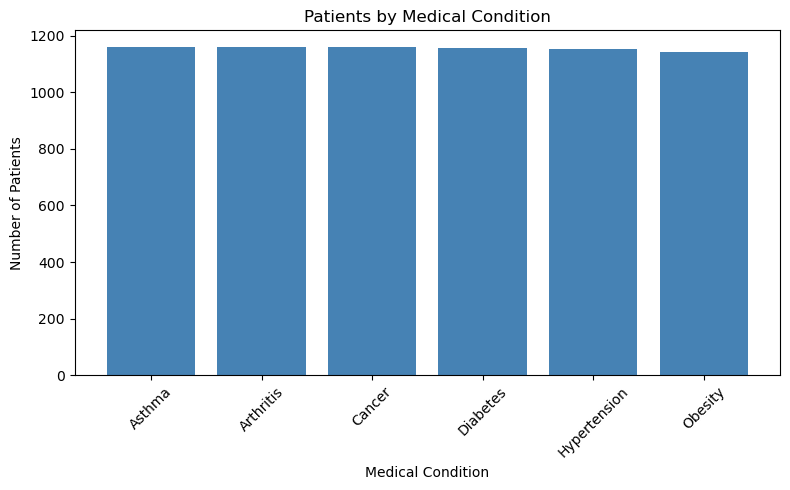

In [34]:
plt.figure(figsize=(8,5))

plt.bar(condition_count.index, condition_count.values, color='steelblue')

plt.title('Patients by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of Patients')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 2. How is patient age distributed across the network 

In [35]:
average_age = df['Age'].mean()
average_age

np.float64(51.89800923254472)

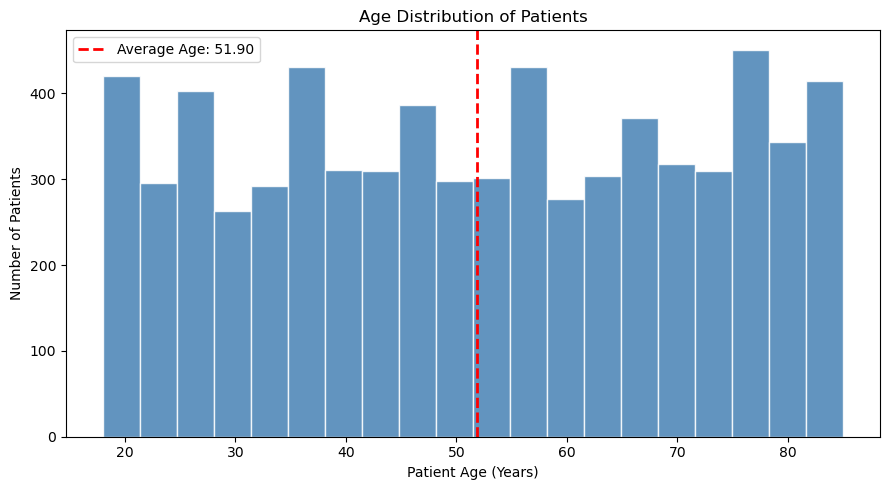

Average Age: 51.9


In [51]:
avg_age = df['Age'].mean()

plt.figure(figsize=(9,5))

plt.hist(
    df['Age'],
    bins=20,
    color='steelblue',
    edgecolor='white',
    alpha=0.85
)

plt.axvline(
    avg_age,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Average Age: {avg_age:.2f}'
)

plt.title('Age Distribution of Patients')
plt.xlabel('Patient Age (Years)')
plt.ylabel('Number of Patients')
plt.legend()
plt.tight_layout()
plt.show()

print("Average Age:", round(avg_age, 2))

#### 3. How has average treatment cost changed over time ?

In [37]:
average_cost = df['Billing Amount'].mean()
average_cost

np.float64(25666.347223942594)

In [ ]:
df['Admission_Month']=df['Date of Admission'].dt.to_period('M')
df[['Test Results'	,'Length_of_stay'	,'Admission_Month']].head()

In [ ]:
df['Admission_Month'] = df['Date of Admission'].dt.to_period('M')

month_avg_cost = df.groupby('Admission_Month')['Billing Amount'].mean()

month_avg_cost

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(month_avg_cost.index.to_timestamp(),
         month_avg_cost.values,
         color='teal',
         marker='o',
         linewidth=2)

plt.title('Monthly Average Treatment Cost')
plt.xlabel('Month')
plt.ylabel('Average Treatment Cost')

plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(interval=6))

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

#### 4. Is there a relationship between patient age and treatment cost

In [52]:
sample_df = df.sample(1000,random_state=1)
sample_df

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
5596,lAUrA HaNSEN,43,Female,B+,Cancer,2022-08-30,Katie Foster,Schroeder-Williams,Cigna,21579.061832,459.0,Elective,2022-09-12,Paracetamol,Normal
2971,chad hArT,76,Female,A-,Arthritis,2021-10-20,Joseph Haley,"Ortiz Lam, Vasquez and",UnitedHealthcare,41091.006370,206.0,Elective,2021-11-18,Penicillin,Normal
1703,Tony OweN,66,Male,B-,Asthma,2024-02-07,John Sanders,Sons Cox and,UnitedHealthcare,40191.729943,102.0,Elective,2024-02-27,Penicillin,Inconclusive
834,brAndY GEORGE,39,Male,A+,Arthritis,2021-10-12,Jennifer Pope,Ryan-Mcneil,Blue Cross,8731.482275,219.0,Emergency,2021-10-27,Ibuprofen,Normal
3354,JOnAThAN bAkEr,33,Male,A-,Cancer,2020-06-13,Emily Gross,LLC Buchanan,UnitedHealthcare,31267.510967,412.0,Elective,2020-06-15,Penicillin,Inconclusive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1271,GLORIA VANCe,28,Female,O+,Asthma,2024-04-25,Mr. Matthew Luna,"Allen Garcia and Wolf,",Medicare,25702.299610,376.0,Elective,2024-05-25,Aspirin,Abnormal
2894,CodY BlaCKWEll,63,Female,A-,Hypertension,2023-10-03,Veronica Gilbert,Bentley Inc,UnitedHealthcare,21101.782890,140.0,Elective,2023-10-24,Aspirin,Normal
5317,ALexIS stEIN,63,Female,A-,Cancer,2022-09-16,Patrick Smith,"Boyd, Gamble and Cruz",Cigna,17600.494036,133.0,Elective,2022-09-30,Aspirin,Normal
4613,DANIEl RamirEZ,36,Female,A+,Cancer,2019-07-21,Justin Freeman,LLC Wolfe,Cigna,40866.767163,302.0,Elective,2019-07-24,Aspirin,Normal


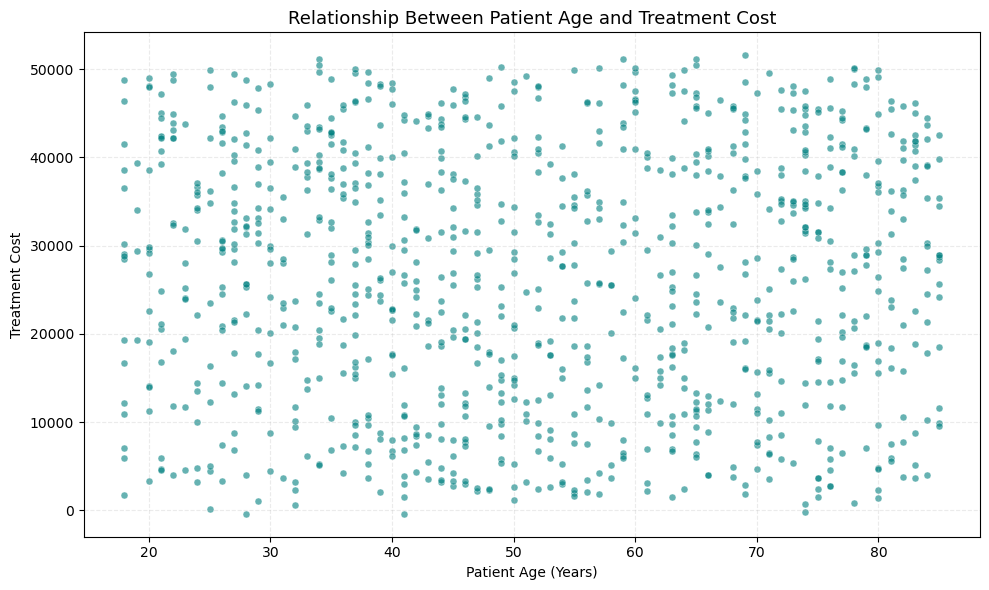

In [56]:
sample_df = df.sample(1000, random_state=1)

plt.figure(figsize=(10,6))

plt.scatter(
    sample_df['Age'],
    sample_df['Billing Amount'],
    color='#008080',
    alpha=0.6,
    s=25,
    edgecolors='white',
    linewidth=0.4
)

plt.title('Relationship Between Patient Age and Treatment Cost', fontsize=13)
plt.xlabel('Patient Age (Years)')
plt.ylabel('Treatment Cost')

plt.grid(axis='both', linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()

#### 5. Which insurance provider covers the most patients

In [59]:
insurance_count = df['Insurance Provider'].value_counts()
insurance_count

Insurance Provider
Cigna               1408
Blue Cross          1400
Medicare            1380
Aetna               1373
UnitedHealthcare    1371
Name: count, dtype: int64

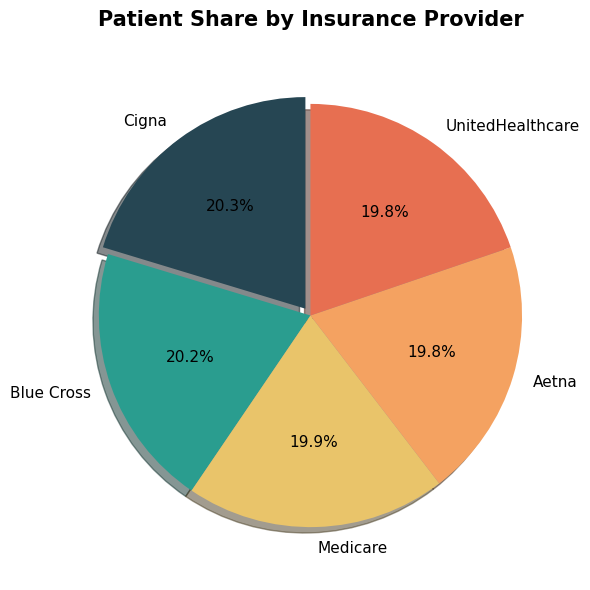

In [61]:
plt.figure(figsize=(8, 6))

plt.pie(
    insurance_count.values,
    labels=insurance_count.index,
    autopct='%1.1f%%',
    colors=['#264653', '#2A9D8F', '#E9C46A', '#F4A261', '#E76F51'],
    startangle=90,
    explode=(0.04, 0, 0, 0, 0),
    shadow=True,
    textprops={'fontsize': 11}
)

plt.title(
    'Patient Share by Insurance Provider',
    fontsize=15,
    fontweight='bold',
    pad=18
)

plt.tight_layout()
plt.show()

# AD-HOC QUESTIONS

## AD-HOC QUESTION 1 — Emergency Department Capacity Planning

**Business Scenario:** Hospital management is planning staffing for emergency cases. They want to know how many emergency admissions occurred in each month.


Monthly Emergency Admissions:
Date of Admission
2019-05    27
2019-06    29
2019-07    34
2019-08    45
2019-09    42
           ..
2024-01    41
2024-02    31
2024-03    50
2024-04    37
2024-05     8
Freq: M, Length: 61, dtype: int64


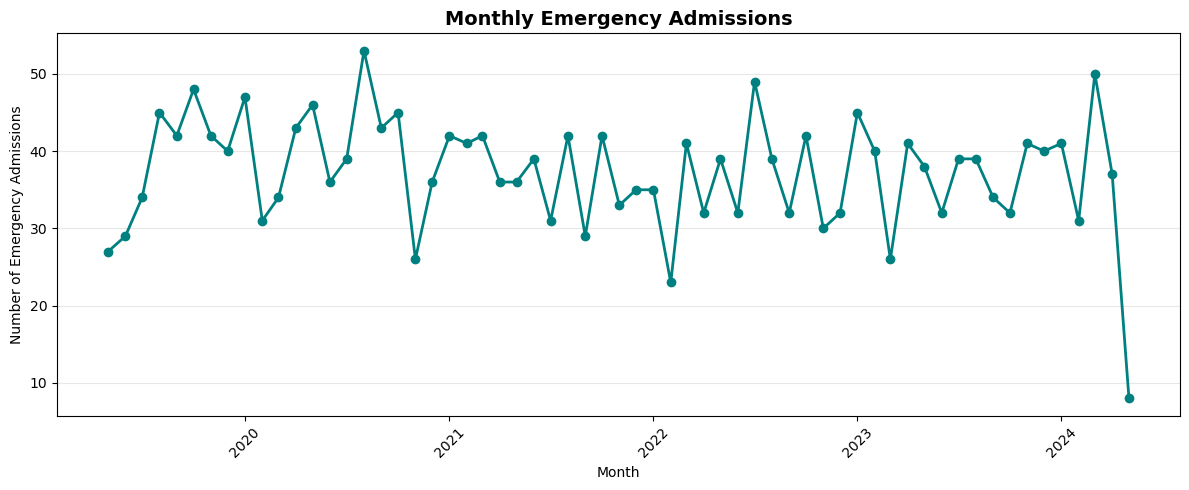

In [64]:
# Convert admission date into datetime
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])

# Filter Emergency admissions
emergency_df = df[df['Admission Type'] == 'Emergency'].copy()

# Count emergency admissions month-wise
monthly_emergency = (
    emergency_df
    .groupby(emergency_df['Date of Admission'].dt.to_period('M'))
    .size()
)

# Display results
print("Monthly Emergency Admissions:")
print(monthly_emergency)

# Visualization
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_emergency.index.to_timestamp(),
    monthly_emergency.values,
    color='teal',
    marker='o',
    linewidth=2
)

plt.title('Monthly Emergency Admissions', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Emergency Admissions')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## AD-HOC QUESTION 2 — Identify High-Cost Patient Groups

**Business Scenario:** The hospital finance team wants to identify patients with unusually high billing amounts so they can review those cases.

In [65]:
# Calculate 95th percentile billing amount
high_cost_limit = df['Billing Amount'].quantile(0.95)

# Filter high-cost patients
high_cost_patients = df[df['Billing Amount'] >= high_cost_limit]

# Display high-cost patient details
print("High-Cost Billing Threshold:", round(high_cost_limit, 2))
print("Number of High-Cost Patients:", len(high_cost_patients))

high_cost_patients[
    ['Name', 'Age', 'Medical Condition', 'Admission Type', 'Billing Amount']
].sort_values(by='Billing Amount', ascending=False)

High-Cost Billing Threshold: 47658.51
Number of High-Cost Patients: 347


,Name,Age,Medical Condition,Admission Type,Billing Amount
5735,DAVId SanDOvaL,22,Hypertension,Emergency,52271.663747
1574,BRETT mARshAll,42,Asthma,Emergency,52181.837792
6663,LAuRie hOod,42,Arthritis,Urgent,52170.036854
323,ashLEy vasQUEZ,30,Asthma,Emergency,51587.936817
6481,TIfFaNy BoWman,69,Arthritis,Emergency,51567.277671
...,...,...,...,...,...
4263,mRS. CAroLINE AcoSTa DDS,54,Cancer,Urgent,47698.371771
4071,joHNnY goNzALEz,32,Diabetes,Emergency,47683.116118
5837,josEPH BaTES,73,Obesity,Urgent,47680.138630
5845,cHrIstopHER GOnZaleZ,44,Obesity,Urgent,47662.633157


In [66]:
# Calculate 95th percentile billing amount
high_cost_limit = df['Billing Amount'].quantile(0.95)

# Filter high-cost patients
high_cost_patients = df[df['Billing Amount'] >= high_cost_limit]

# Display high-cost patient details
print("High-Cost Billing Threshold:", round(high_cost_limit, 2))
print("Number of High-Cost Patients:", len(high_cost_patients))

high_cost_patients[
    ['Name', 'Age', 'Medical Condition', 'Admission Type', 'Billing Amount']
].sort_values(by='Billing Amount', ascending=False)

High-Cost Billing Threshold: 47658.51
Number of High-Cost Patients: 347


,Name,Age,Medical Condition,Admission Type,Billing Amount
5735,DAVId SanDOvaL,22,Hypertension,Emergency,52271.663747
1574,BRETT mARshAll,42,Asthma,Emergency,52181.837792
6663,LAuRie hOod,42,Arthritis,Urgent,52170.036854
323,ashLEy vasQUEZ,30,Asthma,Emergency,51587.936817
6481,TIfFaNy BoWman,69,Arthritis,Emergency,51567.277671
...,...,...,...,...,...
4263,mRS. CAroLINE AcoSTa DDS,54,Cancer,Urgent,47698.371771
4071,joHNnY goNzALEz,32,Diabetes,Emergency,47683.116118
5837,josEPH BaTES,73,Obesity,Urgent,47680.138630
5845,cHrIstopHER GOnZaleZ,44,Obesity,Urgent,47662.633157


# KEY BUSINESS INSIGHTS & CONCLUSION



### Key Findings

1. dentified the most common medical conditions among patients.
2. Analyzed patient age distribution across the healthcare network.
3. Evaluated monthly trends in average treatment costs.
4. Explored the relationship between patient age and billing amount.
5. Compared patient distribution across insurance providers.
6. Analyzed monthly emergency admissions for capacity planning.
7. Identified high-billing patients for financial review.
8. Flagged emergency cases with abnormal test results for further review.

### Conclusion

This project demonstrates how Python can be used to clean, analyze, and visualize healthcare data.

The analysis provides insights into patient demographics, treatment costs, admission patterns, and insurance distribution, helping demonstrate data-driven decision-making in healthcare operations.